# All of the onboarding stuff

## Access form
Go to https://itssc.rpi.edu/hc/en-us/articles/17609648152845-Quantum-computing, click the first link, and follow the instructions given. You should be brought to a page like the following. Go to the link provided and fill out the form. You should receive an email telling you that you have access in a few days. The instructions for signing into an IBM Cloud account should be given with the email. 

![Sign In Form](Form.png)

## Installing Your Environment

### Python and PIP

Go to https://www.python.org/downloads/ and download whichever version of Python you wish to (although the newer versions are probably better). Go through the installation process and you should have a working version of Python. Then, download (Ctrl + S or Command + S) this page https://bootstrap.pypa.io/get-pip.py. Then, go into your terminal and navigate to where you downloaded the file, and use the *python* or *python3* command to install PIP.

![Sign In Form](Pip.png)

### Installing Qiskit

Go into your terminal, enter the following commands.

- pip install qiskit
- pip install qiskit-ibm-runtime
- pip install qiskit-ibm provider

In fact, whenever your code is telling you that something is missing, you should be using PIP to install it. If it tells you those packages are missing after you already used pip, try running the commands with pip3.

### VSCode Setup (Not required but recommended)

It's recommended that you use VSCode, since it has a built in Jupyter notebook environment, which is what we'll be doing most of our work in. You can also use JupyterLabs if you're more comfortable there. After installing VSCode, navigate to the extensions page and install the Python extension. This will be useful for function recommendations and such. 

![Extension for Python](Python_Extension.png)
![Extension for Jupyter](Jupyter_Extension.png)

After that, when you get to executing your code, you need to set the kernel of the notebook. It would ask for a Python version, just select whichever has the Qiskit installation.

![Python Version](Version.png)

# The Code Stuff

In [44]:
from qiskit.circuit import QuantumCircuit
from qiskit.transpiler import generate_preset_pass_manager
from qiskit.visualization import plot_histogram

from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler

## Your API Key and Account

Once you have your account and sign into https://quantum.cloud.ibm.com/, you should be greeted with the following page. 

![IBM Quantum Dashboard](Dashboard.png)

Press the create button by the API key panel, and download the .json file containing the API key. It should look something like this

![API Key](Key.png)

The instance can be copied from the list as seen on the dashboard. Leave the channel as 'ibm_quantum_platform'.

Copy the apikey section (excluding quotations) and paste it into the following code block. If it is your first time and you haven't connected your account yet, use the QiskitRuntimeService.save_account(). Once you have connected your account, comment out the save_account() code and just stick to using QiskitRuntimeService().

In [ ]:
service = QiskitRuntimeService.save_account(
  token='Your apikey', 
  instance='Your instance', 
  channel='ibm_quantum_platform', 
  name='Whatever you want to name this account', 
  set_as_default=True
)
service = QiskitRuntimeService(name='The name you chose for your account')
backend = service.backend(name='ibm_rensselaer')

## The Quantum Circuit

The following circuit we will construct is a basic Bell state. First part is the circuit construction, where first qubit is put into superposition and then entangled with the second qubit. Below is the math that shows the expected result of this operation. 

$$\begin{bmatrix}
1 \\
0 \\
0 \\
0 
\end{bmatrix} = \begin{bmatrix}
1 \\
0
\end{bmatrix} \otimes \begin{bmatrix}
1 \\
0 
\end{bmatrix} \rightarrow \text{Hadamard gate} \rightarrow \frac{1}{\sqrt{2}}\begin{bmatrix}
1 & 1 \\
1 & -1 
\end{bmatrix}\begin{bmatrix}
1 \\
0 
\end{bmatrix} \otimes \begin{bmatrix}
1 \\
0 
\end{bmatrix} = \begin{bmatrix}
\frac{1}{\sqrt{2}} \\
\frac{1}{\sqrt{2}} 
\end{bmatrix} \otimes \begin{bmatrix}
1 \\
0 
\end{bmatrix} = \begin{bmatrix}
\frac{1}{\sqrt{2}} \\
0 \\
\frac{1}{\sqrt{2}} \\
0 
\end{bmatrix} \rightarrow \text{CNOT gate} \rightarrow \begin{bmatrix}
1 & 0 & 0 & 0 \\
0 & 1 & 0 & 0 \\
0 & 0 & 0 & 1 \\
0 & 0 & 1 & 0 
\end{bmatrix}\begin{bmatrix}
\frac{1}{\sqrt{2}} \\
0 \\
\frac{1}{\sqrt{2}} \\
0 
\end{bmatrix} = \begin{bmatrix}
\frac{1}{\sqrt{2}} \\
0 \\
0 \\
\frac{1}{\sqrt{2}} 
\end{bmatrix}$$

As seen above, we represent quantum states as column vectors, each row in the vector representing some state that the system could be in. But, these column vectors could also be seen as the **tensor product** of several column vectors, each representing its own qubit. When you apply a gate to a single qubit, you can sometimes decompose the system into the constituent qubit vectors and perform gates on it. Not always though, because sometimes a column vector cannot be decomposed. 

This is why another notation, known as Bra-Ket notation or Dirac notation, was invented. Instead of writing out the vectors and the matrices, those row and column vectors are written as Bras and Kets, and their combination is the matrices. So, the state $\begin{bmatrix}1 \\ 0 \end{bmatrix}$ is written as $\ket{0}$ and $\begin{bmatrix}0 \\ 1 \end{bmatrix}$ is written as $\ket{1}$. Our initial state is $\ket{00}$, since the both qubits are in state $\ket{0}$ at the start, or as $\ket{0} \otimes \ket{0}$.  

According to the calculations, the result of the Bell state should be equal possibility to measure either 00 or 11 in the two qubit states. 

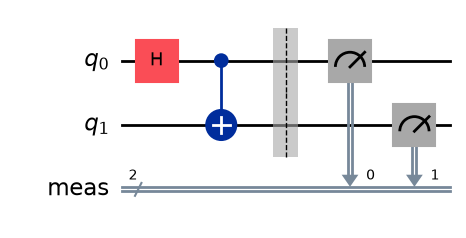

In [ ]:
circuit = QuantumCircuit(2)
circuit.h(0)
circuit.cx(0, 1)

circuit.measure_all()
circuit.draw(output='mpl')

## The ISA Circuit

The Hadamard gate and the CNOT gate are not gates that the quantum computer could physically perform. Which is why, they have to be transformed from virtual gates operations to physical ones. Which is what an ISA circuit is, the Instruction Set Architecture. It defines gates that the computer can run, as well as instructions on timing and such.

We use the generate_preset_pass_manager() function, which automatically creates the ISA circuits. This process is called transpilation, similar to how higher level code needs to be compiled to machine code that the computer can understand. The transpiler function requires two parameters, optimization level and backend. The backend is the one previously defined, which is ibm_rensselaer. The optimization level tell the transpiler function how much abstraction is wanted. The higher the level, the less errors there are going to be, but the more finer details get erased. For a simple circuit like this, the optimization level is not too important.

In [36]:
pm = generate_preset_pass_manager(optimization_level=3, backend=backend)
isa_circuit = pm.run(circuits=circuit)

## Running the Job

After we have the physical circuit, we can finally run the job on the computer. In order to do so, you need to choose a Qiskit primitive. Think of the primitive like choosing how you want to view your data when you get it back. There are two primitives, Sampler and Estimator. Sampler returns a histogram that shows which end state got how many hits. Estimator on the other hand, returns the expectation value, or the average of the computed value we got based on an observable. We will go more into detail on Estimators later on. 

In [ ]:
sampler = Sampler(mode=backend)
job = sampler.run([isa_circuit])
print(f"Job ID: {job.job_id()}")

In [ ]:
results = service.job(job_id='Copy whatever is printed out from the previous cell').result()
data = results[0].data.meas.get_counts()

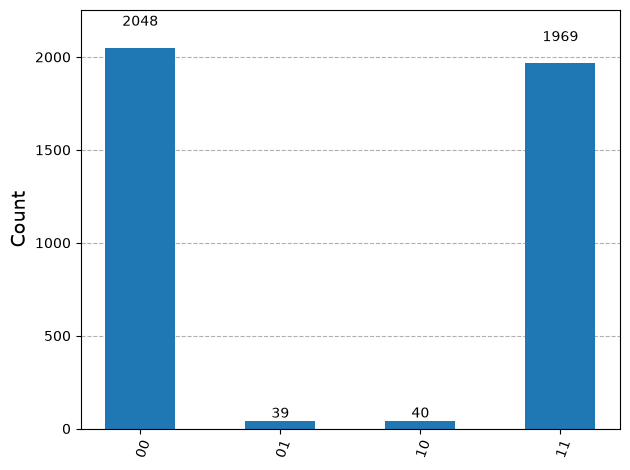

In [48]:
plot_histogram(data=data)

## Interpreting the Results

Earlier, the calculations established that the only things that should be measured are states 00 and 11, with half probability for each. As seen in the histogram, the results skew heavily towards those two states. There are some measurements of 01 or 11, but those are just the results of noise. So, this verifies that our calculations are right.